В цьому ноутбуці відбуваєтся перевірка одного активу на рандомних відрізках часу. Метою є перевірка чи отримані загальні результати релевантні для різних режимів ринку

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np

import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2020-01-01,7200.174316,130.802002,NaN,0.192667,0.002033,0.033458,NaN,1.806640,0.045451,45.753544
2020-01-02,6985.470215,127.410179,NaN,0.188043,0.002009,0.032751,NaN,1.741144,0.044112,45.749470
2020-01-03,7344.884277,134.171707,NaN,0.193521,0.002145,0.034180,NaN,1.809708,0.045234,51.092037
2020-01-04,7410.656738,135.069366,NaN,0.194355,0.002241,0.034595,NaN,1.840133,0.046272,50.536694
2020-01-05,7411.317383,136.276779,NaN,0.195537,0.002419,0.034721,NaN,1.807787,0.045359,54.096893
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
df_stocks.columns

Index(['BTC', 'ETH', 'SOL', 'XRP', 'DOGE', 'ADA', 'DOT', 'LINK', 'XLM', 'XMR'], dtype='str')

In [5]:
target_asset = "DOT"
asset_prices = df_stocks[target_asset].dropna()

n_periods = 10
sequence_length = 365 * 3

periods = []
for i in range(n_periods):
    start = random.randint(0, len(asset_prices) - sequence_length)
    period_prices = asset_prices.iloc[start:start + sequence_length]
    periods.append({
        "period_id": i + 1,
        "start": period_prices.index.min(),
        "end": period_prices.index.max(),
        "prices": period_prices,
    })

In [6]:
pd.DataFrame(
    [{"period": p["period_id"], "start": p["start"], "end": p["end"], "days": len(p["prices"])} for p in periods]
 )

,period,start,end,days
0,1,2021-05-01,2024-04-29,1095
1,2,2020-12-29,2023-12-28,1095
2,3,2023-06-17,2026-06-15,1095
3,4,2022-05-31,2025-05-29,1095
4,5,2023-05-26,2026-05-24,1095
5,6,2020-10-10,2023-10-09,1095
6,7,2023-09-28,2026-09-26,1095
7,8,2023-02-03,2026-02-01,1095
8,9,2021-02-26,2024-02-25,1095
9,10,2022-02-23,2025-02-21,1095


In [7]:
strategy = {
    "buy_amount": 10,
}

01:01:22 - cmdstanpy - INFO - Chain [1] start processing
01:01:22 - cmdstanpy - INFO - Chain [1] done processing


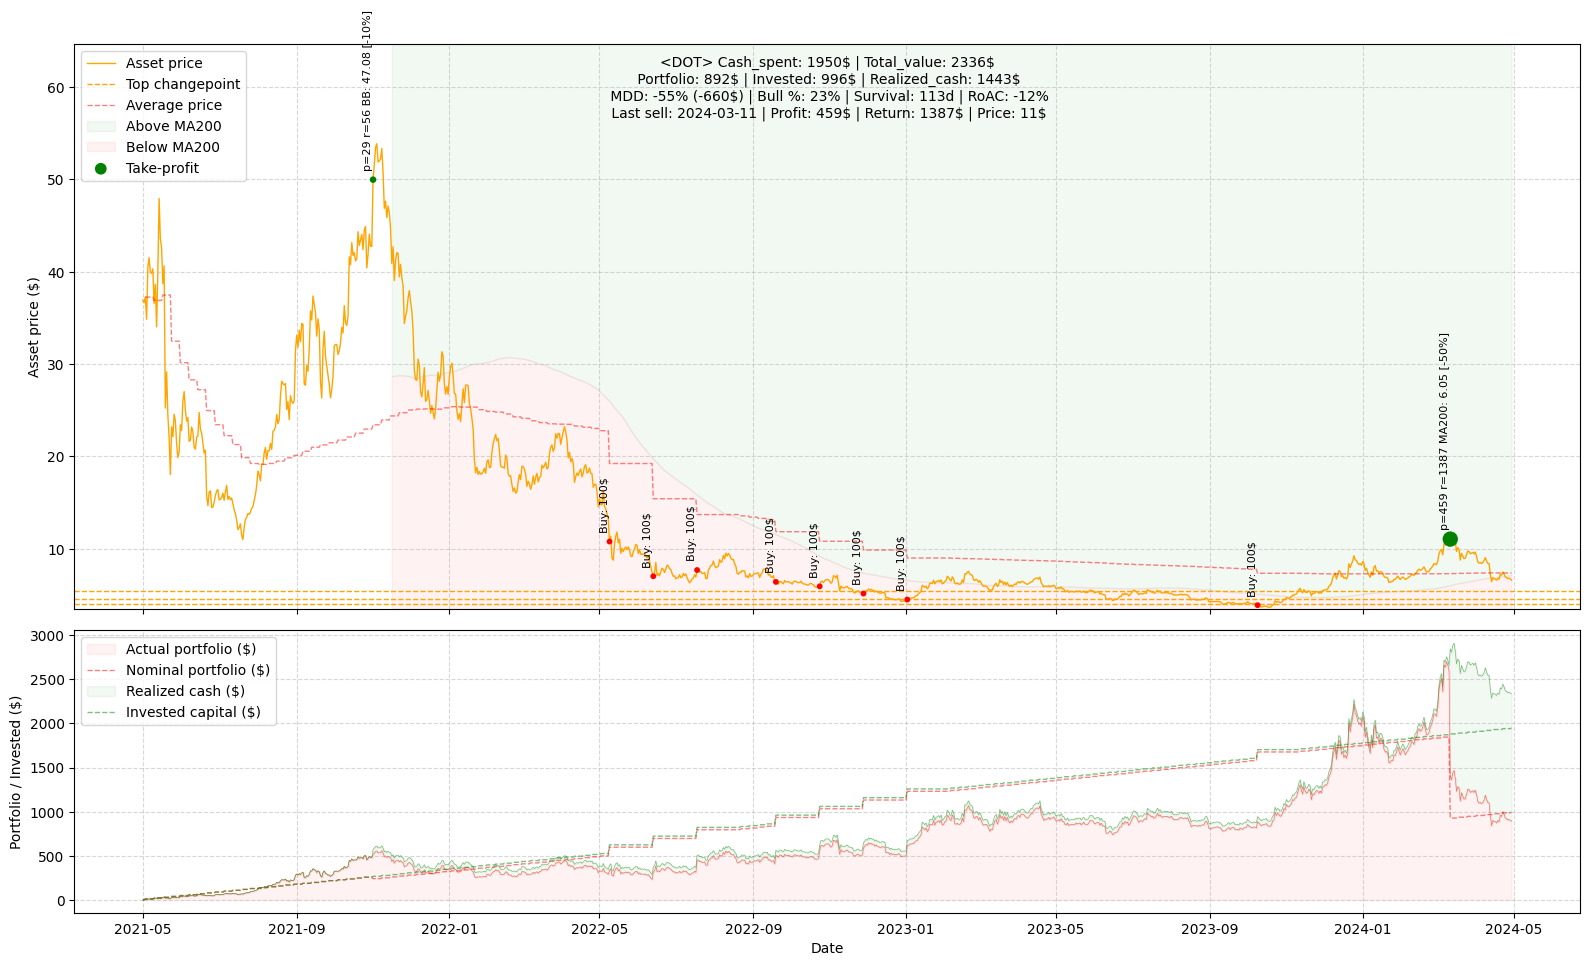

01:01:22 - cmdstanpy - INFO - Chain [1] start processing
01:01:23 - cmdstanpy - INFO - Chain [1] done processing


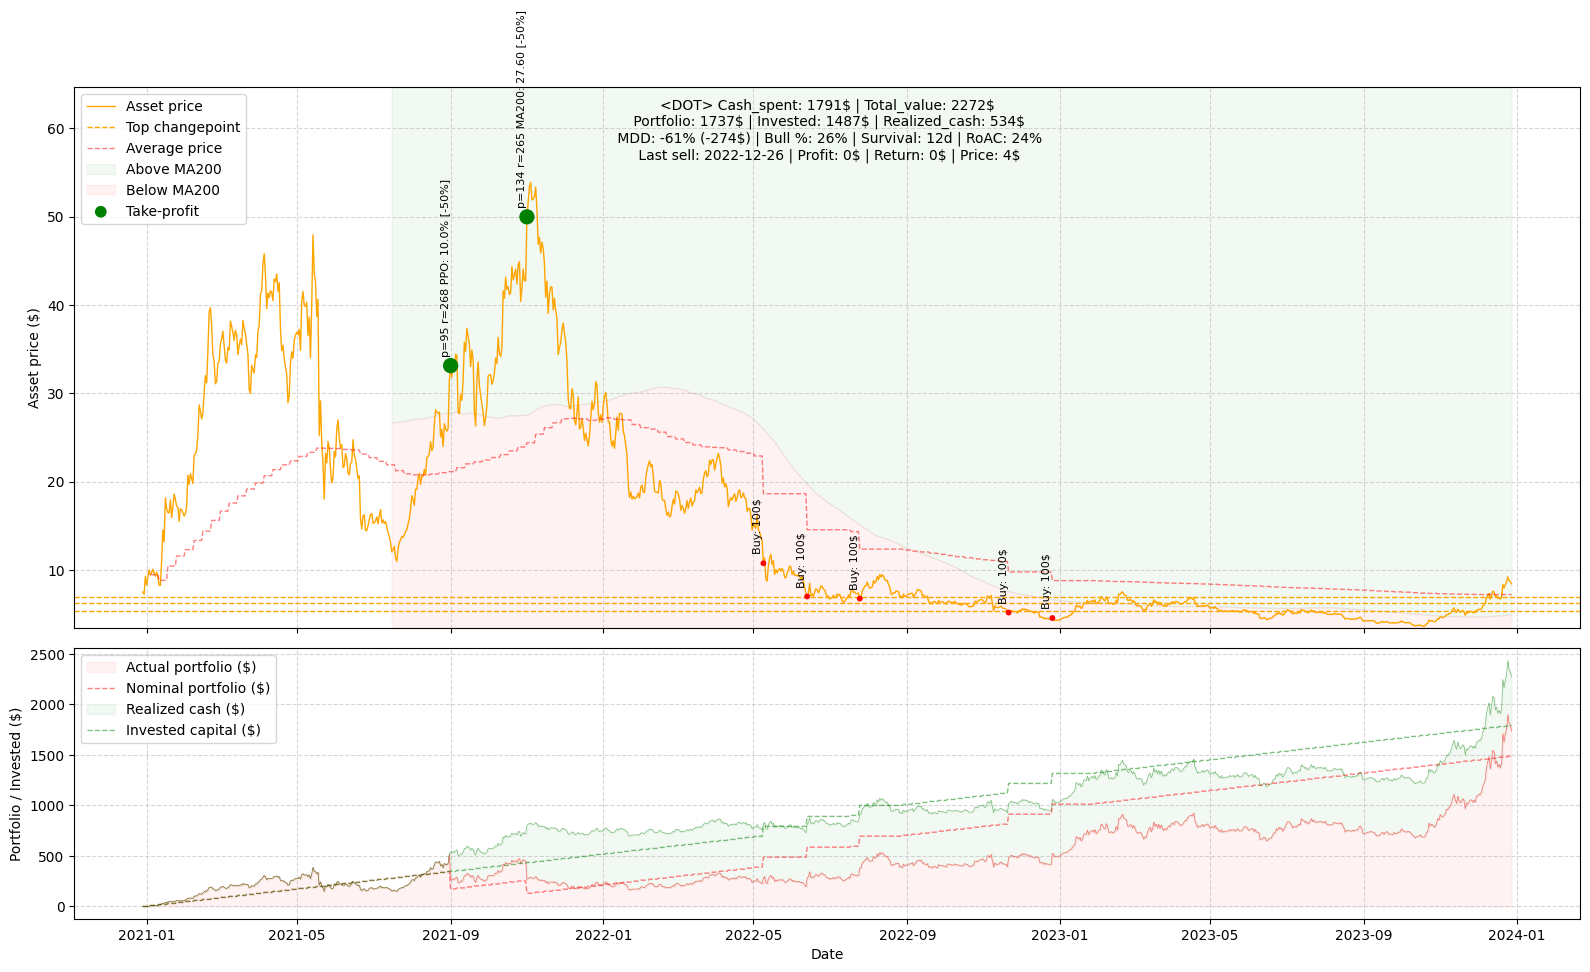

01:01:23 - cmdstanpy - INFO - Chain [1] start processing
01:01:23 - cmdstanpy - INFO - Chain [1] done processing


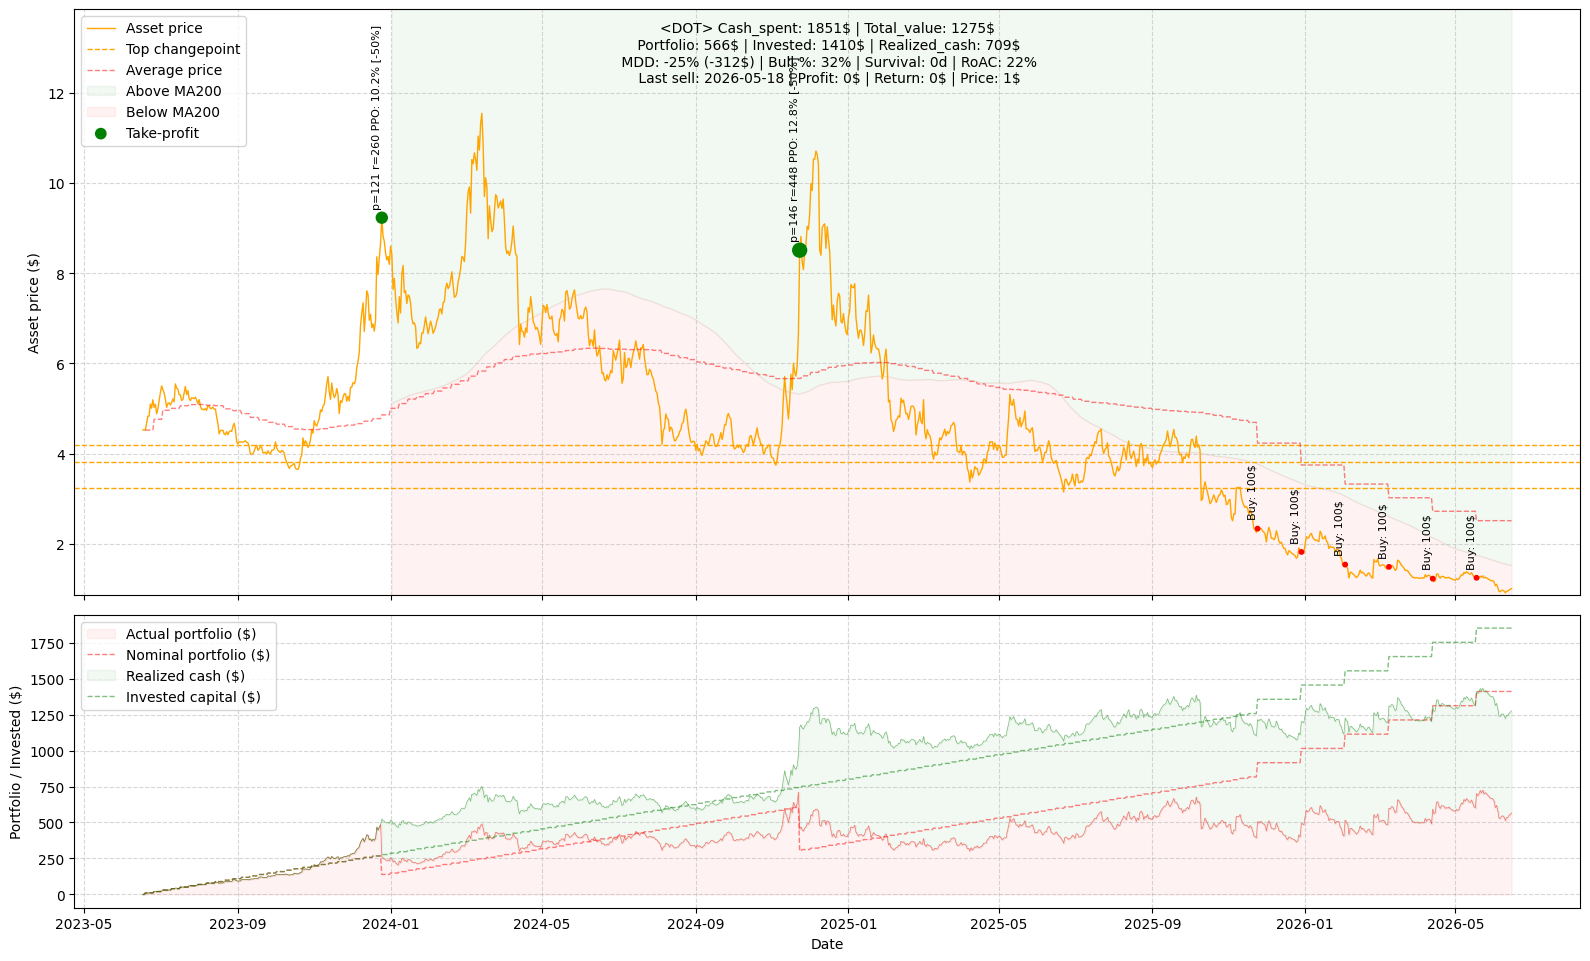

01:01:23 - cmdstanpy - INFO - Chain [1] start processing
01:01:23 - cmdstanpy - INFO - Chain [1] done processing


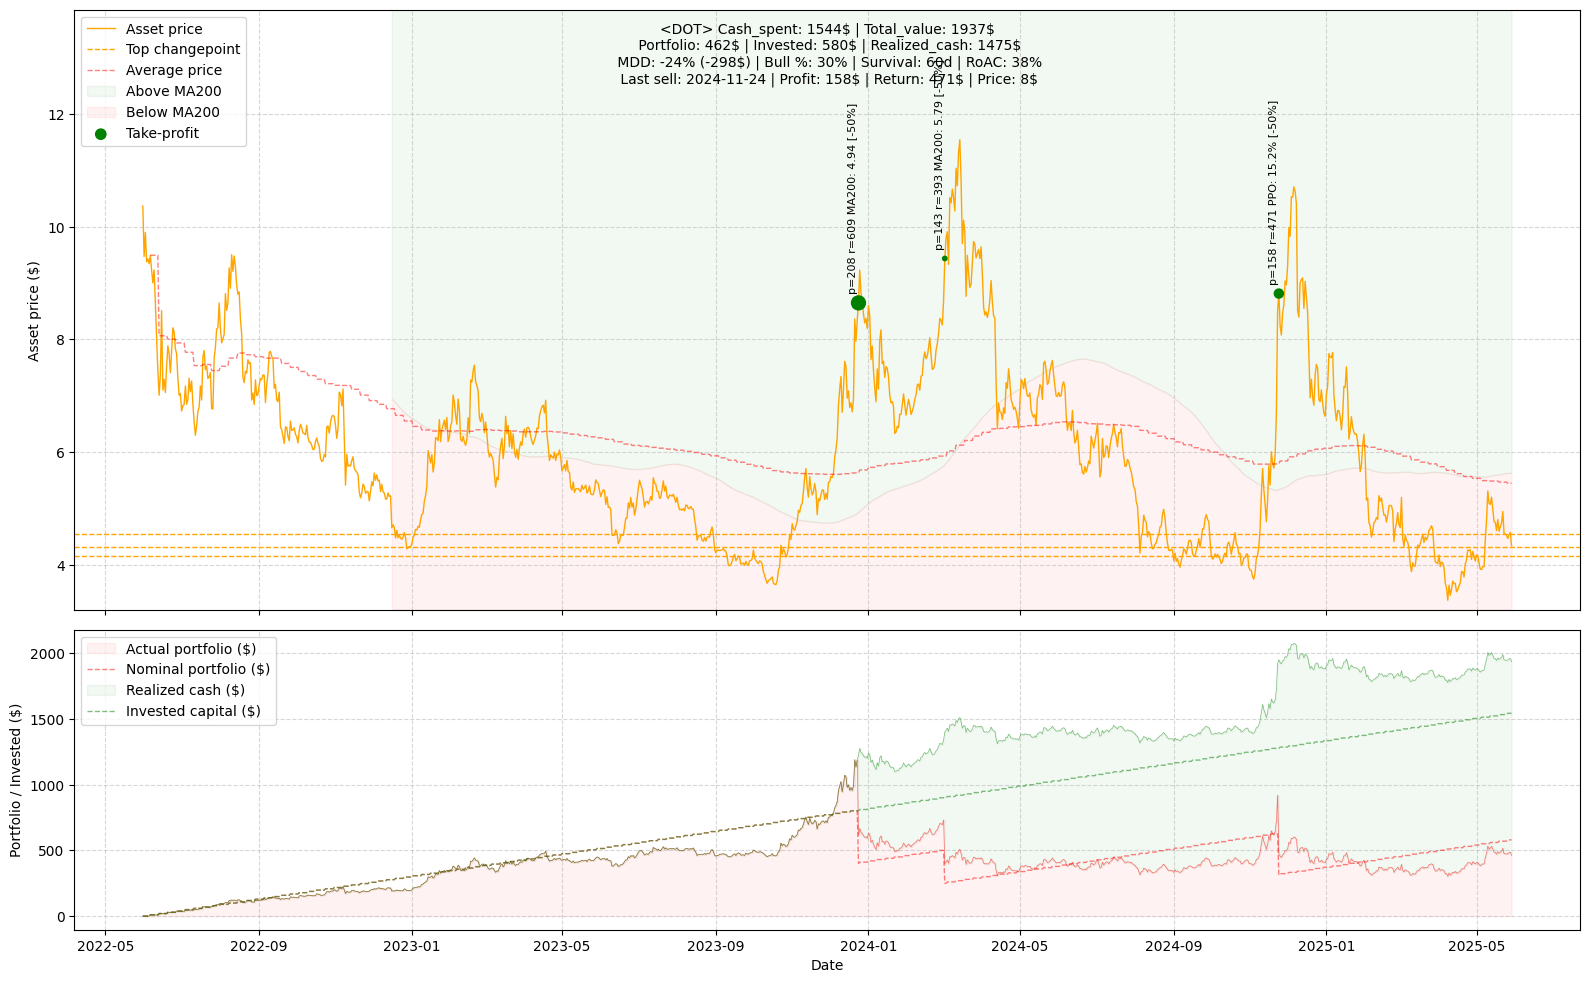

01:01:24 - cmdstanpy - INFO - Chain [1] start processing
01:01:24 - cmdstanpy - INFO - Chain [1] done processing


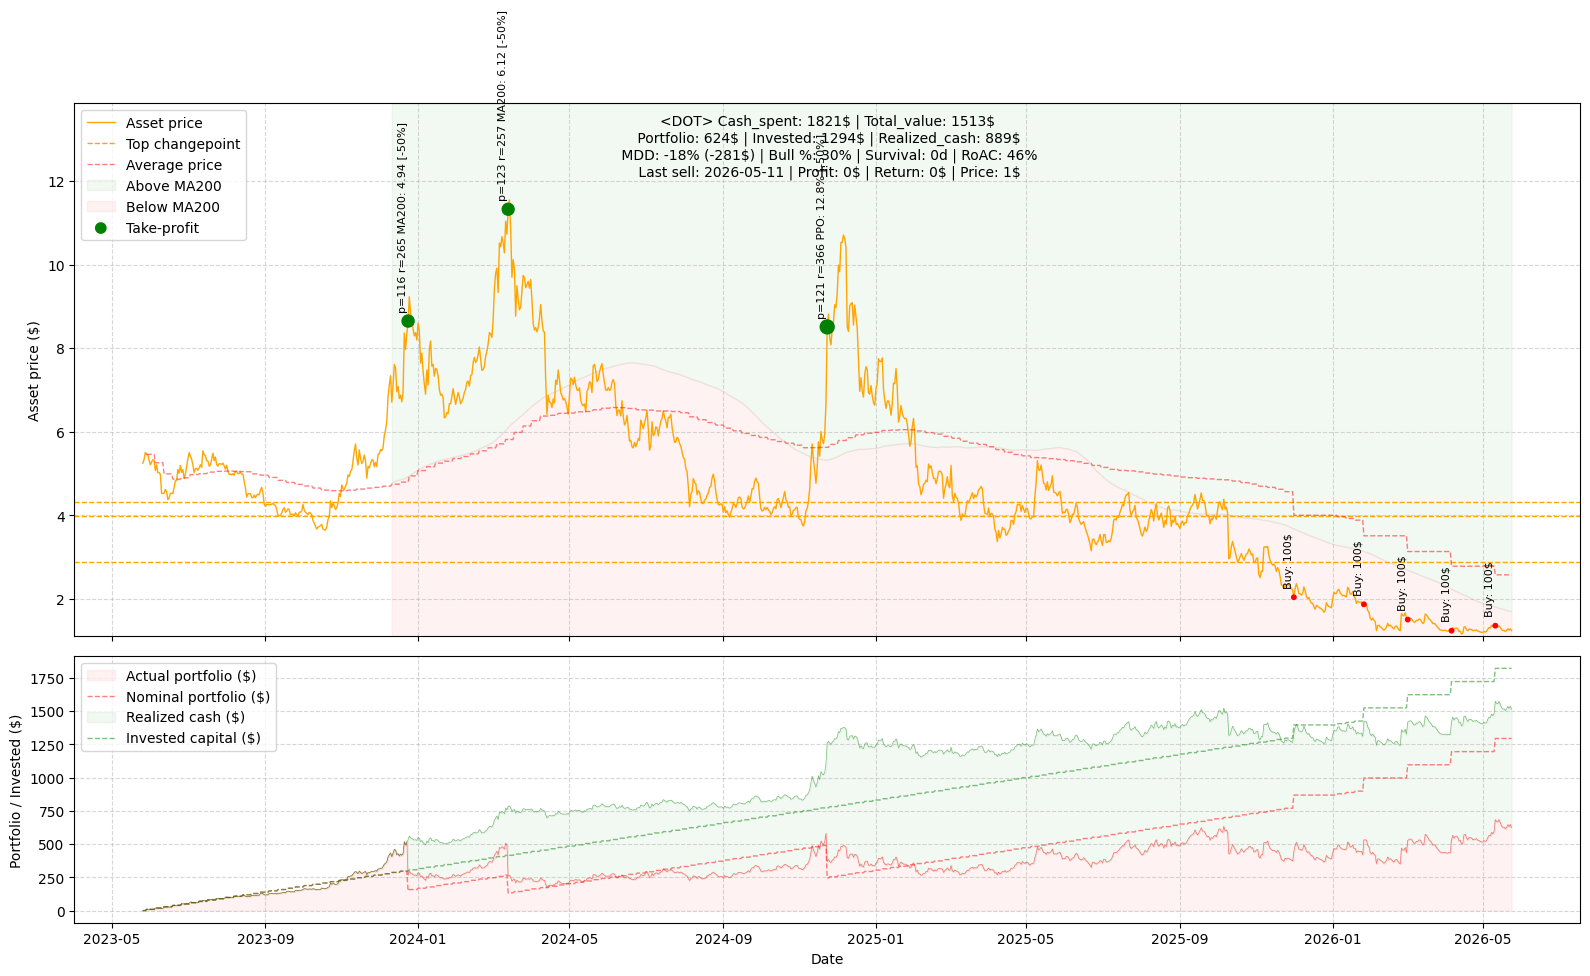

01:01:24 - cmdstanpy - INFO - Chain [1] start processing
01:01:24 - cmdstanpy - INFO - Chain [1] done processing


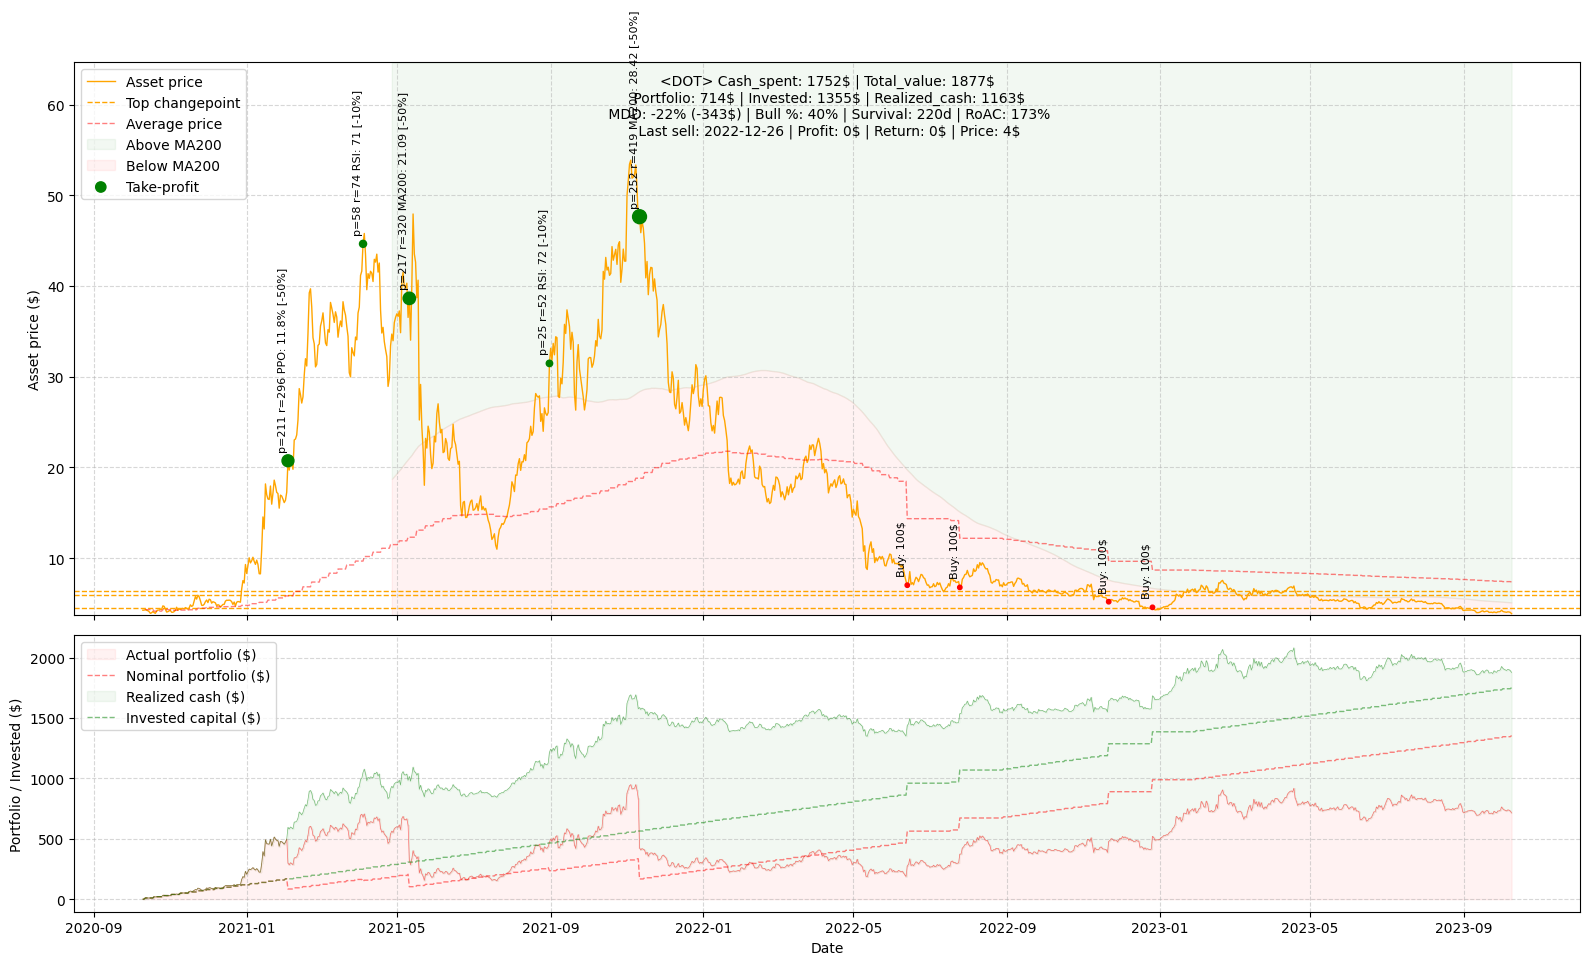

01:01:25 - cmdstanpy - INFO - Chain [1] start processing
01:01:25 - cmdstanpy - INFO - Chain [1] done processing


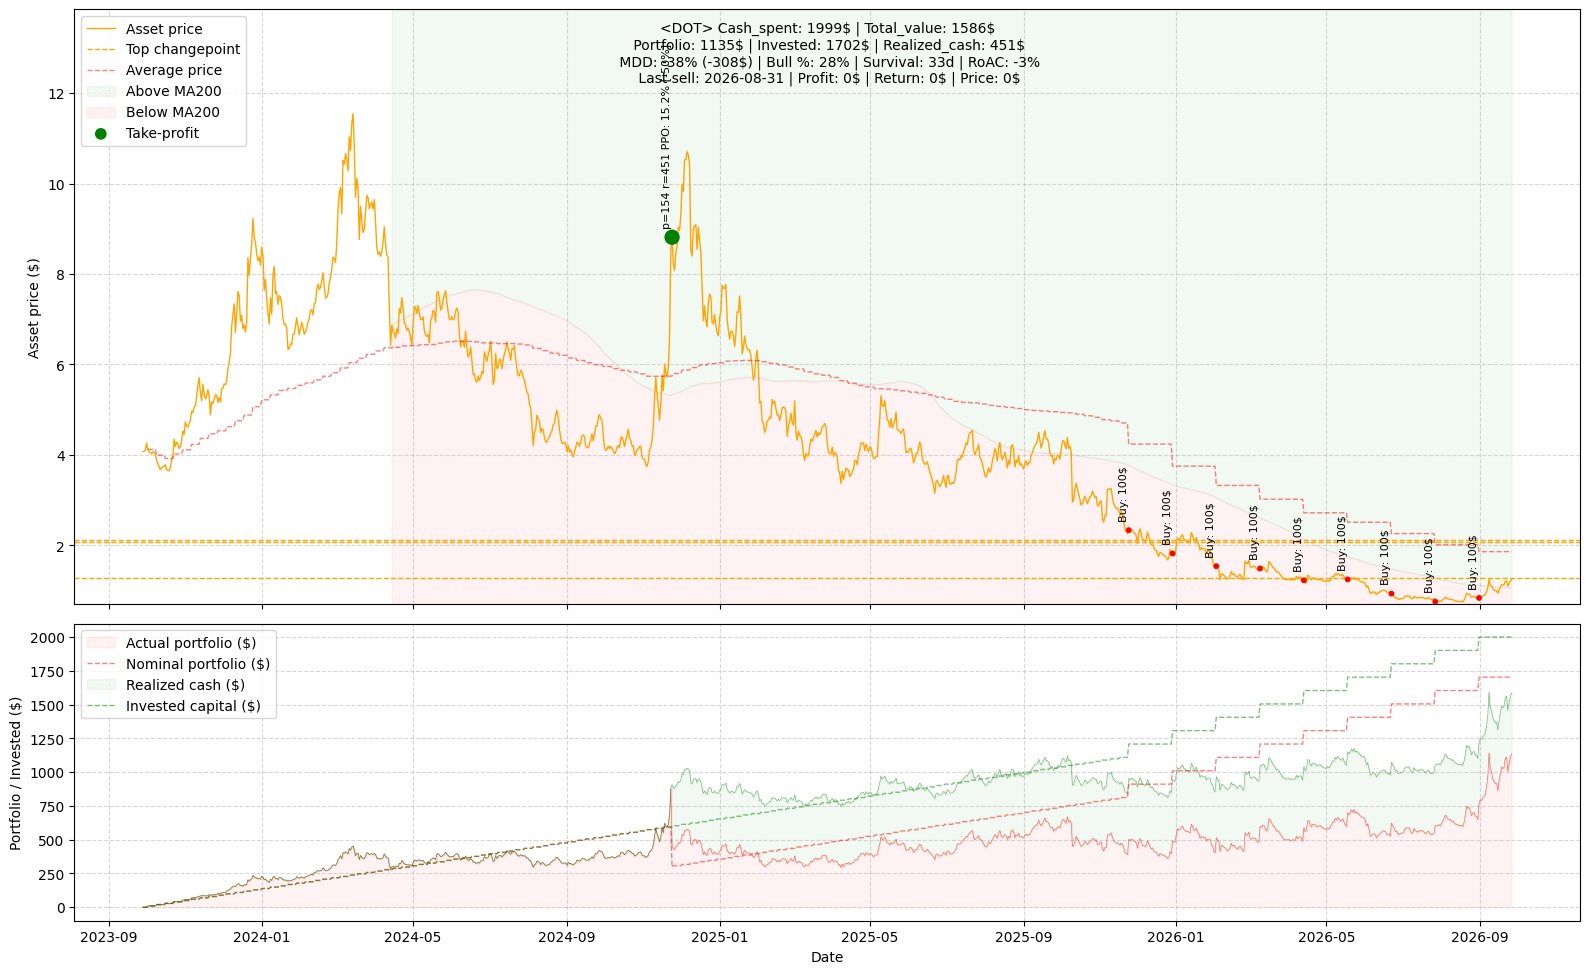

01:01:25 - cmdstanpy - INFO - Chain [1] start processing
01:01:26 - cmdstanpy - INFO - Chain [1] done processing


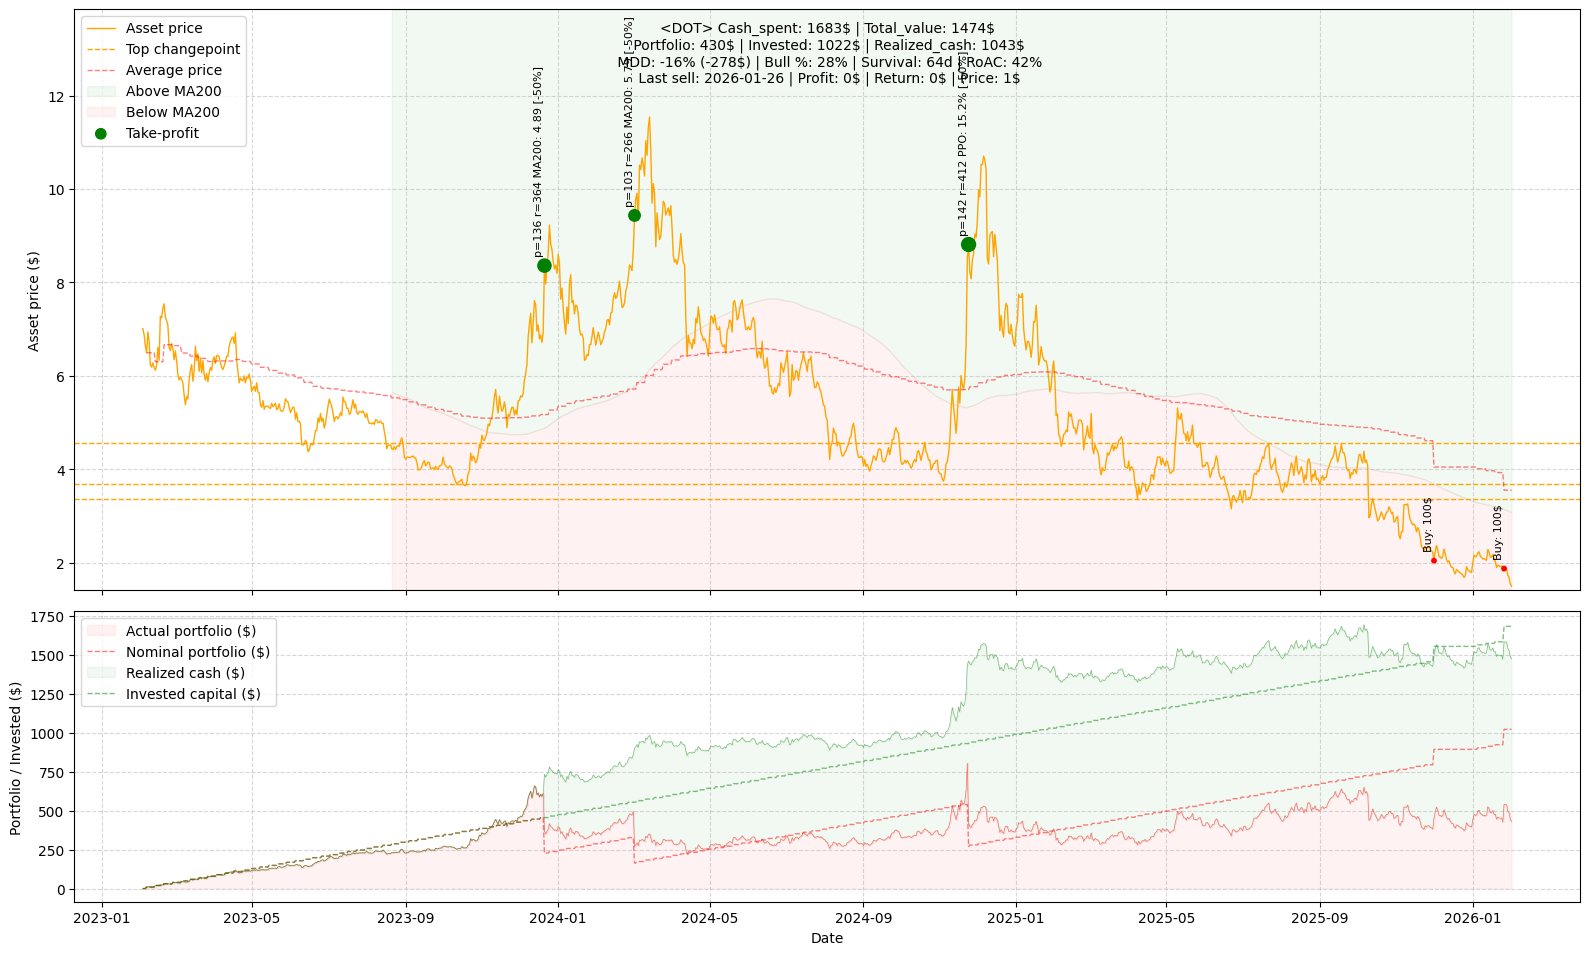

01:01:26 - cmdstanpy - INFO - Chain [1] start processing
01:01:26 - cmdstanpy - INFO - Chain [1] done processing


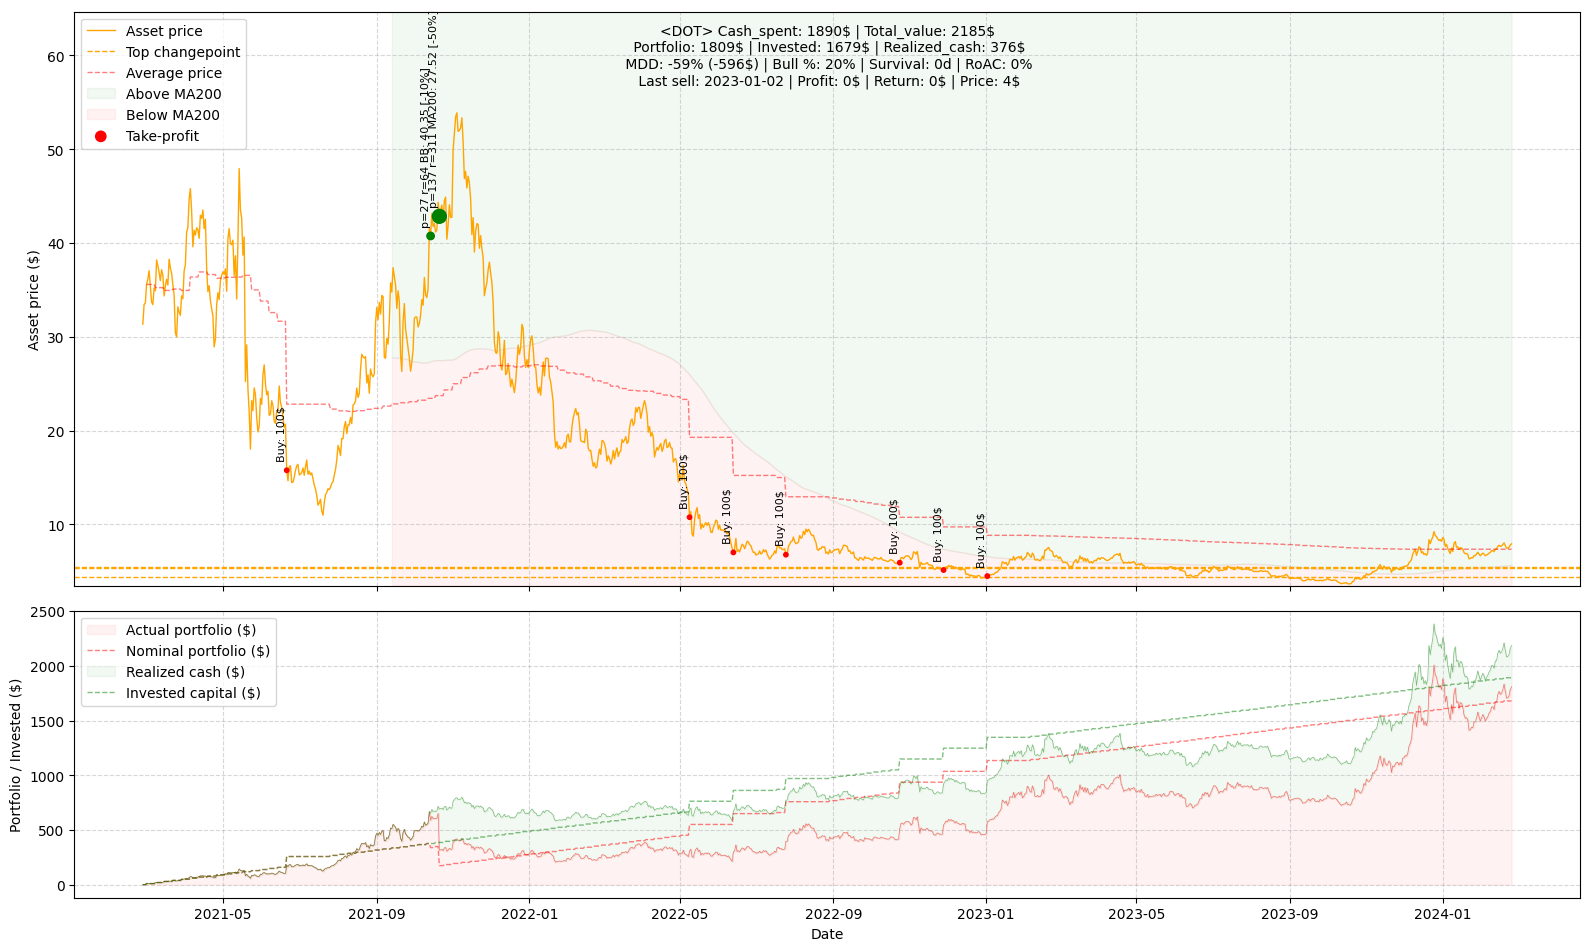

01:01:26 - cmdstanpy - INFO - Chain [1] start processing
01:01:27 - cmdstanpy - INFO - Chain [1] done processing


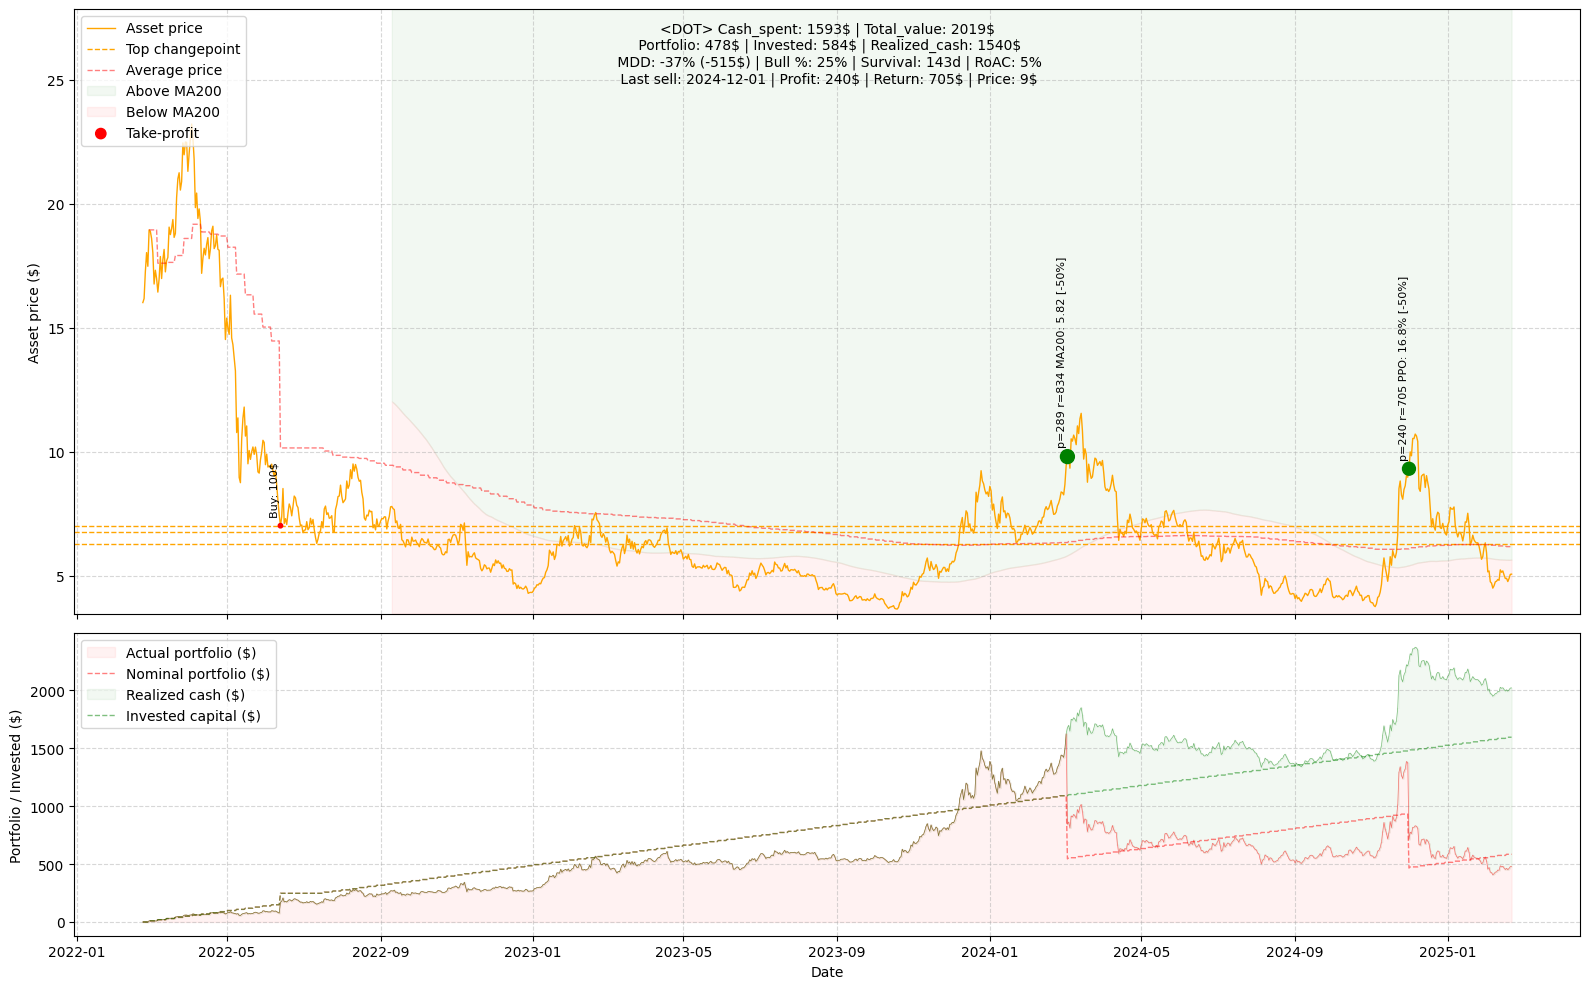

,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,Period,Start,End
0,DOT,1950,1443,892,996,2336,23,7.356725,10,-55,-660,113.2,-12,1,2021-05-01,2024-04-29
1,DOT,1791,534,1737,1487,2272,26,7.232542,7,-61,-274,12.0,24,2,2020-12-29,2023-12-28
2,DOT,1851,709,566,1410,1275,32,2.515423,8,-25,-312,0.0,22,3,2023-06-17,2026-06-15
3,DOT,1544,1475,462,580,1937,30,5.448172,3,-24,-298,60.5,38,4,2022-05-31,2025-05-29
4,DOT,1821,889,624,1294,1513,30,2.579124,8,-18,-281,0.0,46,5,2023-05-26,2026-05-24
5,DOT,1752,1163,714,1355,1877,40,7.357498,9,-22,-343,220.0,173,6,2020-10-10,2023-10-09
6,DOT,1999,451,1135,1702,1586,28,1.863533,10,-38,-308,33.0,-3,7,2023-09-28,2026-09-26
7,DOT,1683,1043,430,1022,1474,28,3.552729,5,-16,-278,63.5,42,8,2023-02-03,2026-02-01
8,DOT,1890,376,1809,1679,2185,20,7.352542,9,-59,-596,0.0,0,9,2021-02-26,2024-02-25
9,DOT,1593,1540,478,584,2019,25,6.165941,3,-37,-515,143.0,5,10,2022-02-23,2025-02-21


In [8]:
all_metrics = []
last_result = None
last_metrics = None

for p in periods:
    period_prices = p["prices"]

    try:
        bt = BacktestDCA(
        target=target_asset,
        prices=period_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {target_asset} on period {p['period_id']}: {e}")
        continue

    metrics = metrics.copy()
    metrics["Period"] = p["period_id"]
    metrics["Start"] = p["start"]
    metrics["End"] = p["end"]
    all_metrics.append(metrics)

    last_result = result
    last_metrics = metrics

summary = pd.DataFrame(all_metrics)
summary

In [9]:
last_result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-02-23,16.009569,0.000000,0.0,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-24,16.170918,0.000000,0.0,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-25,17.250305,0.000000,0.0,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-26,18.024559,0.000000,0.0,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-27,17.473413,0.000000,0.0,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2025-02-17,4.888373,94.730073,584.1,1593.9,0.0,0.0,1540.171117,,463.075922,6.165941,2003.247039
2025-02-18,4.758246,94.730073,584.1,1593.9,0.0,0.0,1540.171117,,450.748986,6.165941,1990.920103
2025-02-19,4.882347,94.730073,584.1,1593.9,0.0,0.0,1540.171117,,462.505098,6.165941,2002.676215


In [10]:
last_metrics

{'Target': 'DOT',
 'Cash_spent': 1593,
 'Realized_cash': 1540,
 'Portfolio': 478,
 'Invested': 584,
 'Total_value': 2019,
 'Bull_history': 25,
 'Avg_price': np.float64(6.16594055871612),
 'Num_take_profits': 3,
 'MDD': -37,
 'MDD_usd': -515,
 'MA200_survival_days': 143.0,
 'RoAC': 5,
 'Period': 10,
 'Start': Timestamp('2022-02-23 00:00:00'),
 'End': Timestamp('2025-02-21 00:00:00')}